In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 5)

In [3]:
columns = [
    "key",
    "pickup_datetime",
    "fare_amount",
    "dropoff_datetime",
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count"
]

df = pd.read_csv("uber.csv", header=None, names=columns)

print("Dimensions du dataset :", df.shape)
display(df.head())
print("\nInformations générales :")
df.info()

Dimensions du dataset : (200001, 9)


/tmp/ipykernel_1305/3891357822.py:13: DtypeWarning: Columns (0: fare_amount, 1: pickup_longitude, 2: pickup_latitude, 3: dropoff_longitude, 4: dropoff_latitude, 5: passenger_count) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("uber.csv", header=None, names=columns)


,key,pickup_datetime,fare_amount,dropoff_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,NaN,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
1,24238194.0,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.99981689453125,40.73835372924805,-73.99951171875,40.72321701049805,1
2,27835199.0,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.99471,40.750325,1
3,44984355.0,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.74077,-73.962565,40.772647,1
4,25894730.0,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3



Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 200001 entries, 0 to 200000
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   key                200000 non-null  float64
 1   pickup_datetime    200001 non-null  str    
 2   fare_amount        200001 non-null  object 
 3   dropoff_datetime   200001 non-null  str    
 4   pickup_longitude   200001 non-null  object 
 5   pickup_latitude    200001 non-null  object 
 6   dropoff_longitude  200000 non-null  object 
 7   dropoff_latitude   200000 non-null  object 
 8   passenger_count    200001 non-null  object 
dtypes: float64(1), object(6), str(2)
memory usage: 13.7+ MB


In [4]:
print("Valeurs manquantes par colonne :")
display(df.isna().sum().to_frame("valeurs_manquantes"))

print("\nStatistiques descriptives :")
display(df.describe(include="all").T)

Valeurs manquantes par colonne :


,valeurs_manquantes
key,1
pickup_datetime,0
fare_amount,0
dropoff_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,1
dropoff_latitude,1
passenger_count,0



Statistiques descriptives :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
key,200000.0,NaN,NaN,NaN,27712503.68235,16013822.212829,1.0,13825346.25,27745495.0,41555300.75,55423567.0
pickup_datetime,200001,200001,key,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fare_amount,200001.0,1861.0,6.5,6580.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dropoff_datetime,200001,196630,2009-02-12 12:46:00 UTC,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_longitude,200001.0,100522.0,0.0,2572.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pickup_latitude,200001.0,113018.0,0.0,2571.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dropoff_longitude,200000.0,105854.0,0.0,2566.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dropoff_latitude,200000.0,118850.0,0.0,2562.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
passenger_count,200001.0,16.0,1.0,93005.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Convertir les colonnes numeriques ; les valeurs invalides deviennent NaN
numeric_cols = [
    "fare_amount", "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude", "passenger_count"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convertir la date de prise en charge
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)

# Supprimer les lignes où les variables essentielles sont absentes
required_cols = [
    "pickup_datetime", "fare_amount",
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude", "passenger_count"
]
df = df.dropna(subset=required_cols).copy()

# Garder des valeurs plausibles : prix positif, coordonnees autour de New York,
# nombre de passagers entre 1 et 6
df = df[
    (df["fare_amount"] > 0) &
    df["pickup_longitude"].between(-75, -72) &
    df["dropoff_longitude"].between(-75, -72) &
    df["pickup_latitude"].between(40, 42) &
    df["dropoff_latitude"].between(40, 42) &
    (df["passenger_count"].between(1, 6))
].copy()

print("Dimensions après nettoyage :", df.shape)
display(df.head())

/tmp/ipykernel_1305/2587739744.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)


Dimensions après nettoyage : (195100, 9)


,key,pickup_datetime,fare_amount,dropoff_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
1,24238194.0,2015-05-07 19:52:06.000000300+00:00,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1.0
2,27835199.0,2009-07-17 20:04:56.000000200+00:00,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1.0
3,44984355.0,2009-08-24 21:45:00.000000610+00:00,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1.0
4,25894730.0,2009-06-26 08:22:21.000000100+00:00,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3.0
5,17610152.0,2014-08-28 17:47:00.000000188+00:00,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5.0


In [6]:
def haversine_km(lon1, lat1, lon2, lat2):
    # Conversion degrés -> radians
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])

    dlon = lon2 - lon1
    dlat = lat2 - lat1

    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine_km(
    df["pickup_longitude"],
    df["pickup_latitude"],
    df["dropoff_longitude"],
    df["dropoff_latitude"]
)

# Éliminer les distances nulles ou anormalement grandes et les prix extrêmes
df = df[
    df["distance_km"].between(0.1, 100) &
    (df["fare_amount"] <= 100)
].copy()

print("Dimensions après filtrage de la distance et du prix :", df.shape)
display(df[["distance_km", "fare_amount"]].describe())

Dimensions après filtrage de la distance et du prix : (191843, 10)


,distance_km,fare_amount
count,191843.000000,191843.000000
mean,3.376451,11.290019
std,3.702087,9.283392
min,0.100227,0.010000
25%,1.294753,6.000000
50%,2.192669,8.500000
75%,3.955804,12.500000
max,99.162509,100.000000


In [7]:
df["hour"] = df["pickup_datetime"].dt.hour
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek
df["month"] = df["pickup_datetime"].dt.month

features = [
    "distance_km",
    "hour",
    "day_of_week",
    "month",
    "passenger_count"
]
target = "fare_amount"

X = df[features]
y = df[target]

print("Variables explicatives :", features)
print("Nombre d'exemples :", len(df))

Variables explicatives : ['distance_km', 'hour', 'day_of_week', 'month', 'passenger_count']
Nombre d'exemples : 191843


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)

Taille de X_train : (153474, 5)
Taille de X_test  : (38369, 5)


In [9]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Régression linéaire")
print(f"MAE  : {mae_linear:.3f}")
print(f"RMSE : {rmse_linear:.3f}")
print(f"R²   : {r2_linear:.3f}")

Régression linéaire
MAE  : 2.305
RMSE : 4.340
R²   : 0.779


In [10]:
# n_estimators=100 : 100 arbres de décision
# n_jobs=-1 : utiliser les cœurs disponibles du processeur
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print(f"MAE  : {mae_rf:.3f}")
print(f"RMSE : {rmse_rf:.3f}")
print(f"R²   : {r2_rf:.3f}")

Random Forest
MAE  : 2.317
RMSE : 4.126
R²   : 0.800


In [11]:
comparison = pd.DataFrame({
    "Modèle": ["Régression linéaire", "Random Forest"],
    "MAE": [mae_linear, mae_rf],
    "RMSE": [rmse_linear, rmse_rf],
    "R²": [r2_linear, r2_rf]
})

display(comparison.sort_values("RMSE"))

,Modèle,MAE,RMSE,R²
1,Random Forest,2.316709,4.125512,0.800359
0,Régression linéaire,2.305060,4.339585,0.779103


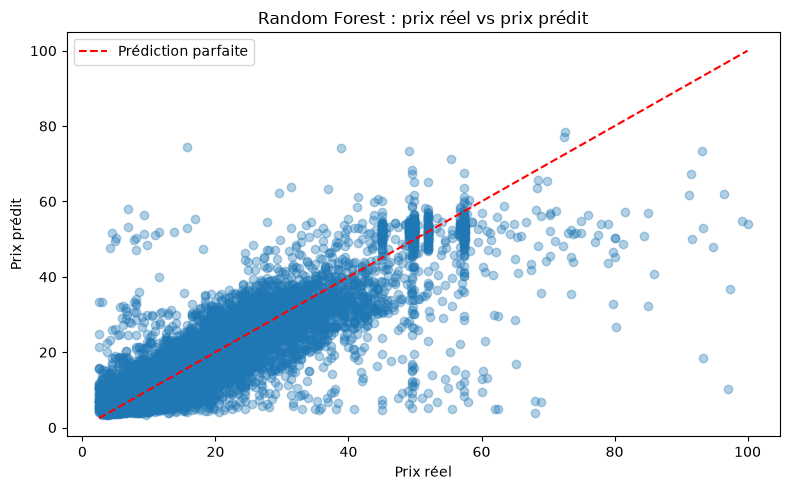

In [12]:
plt.figure()
plt.scatter(y_test, y_pred_rf, alpha=0.35)
min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--", label="Prédiction parfaite")
plt.xlabel("Prix réel")
plt.ylabel("Prix prédit")
plt.title("Random Forest : prix réel vs prix prédit")
plt.legend()
plt.tight_layout()
plt.show()

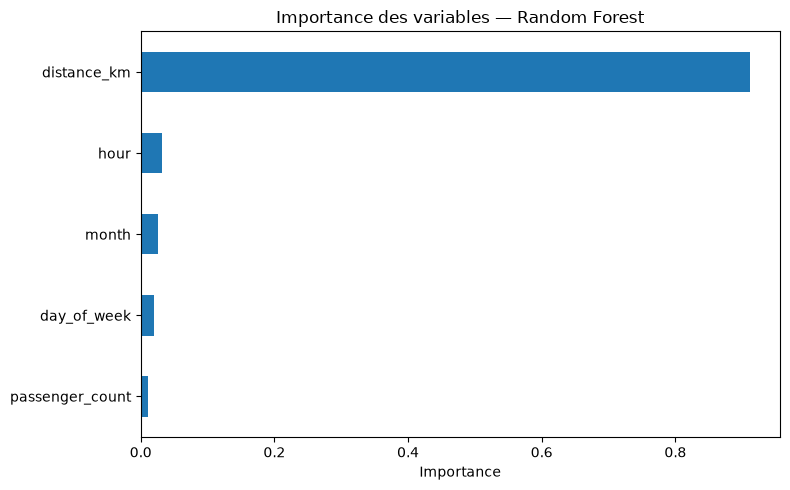

,importance
distance_km,0.911036
hour,0.032230
month,0.026073
day_of_week,0.019453
passenger_count,0.011208


In [13]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=True)

plt.figure()
importance.plot(kind="barh")
plt.xlabel("Importance")
plt.title("Importance des variables — Random Forest")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("importance"))

In [14]:
# Exemple fictif : trajet de 5 km, prise en charge à 18 h,
# un mardi (day_of_week=1), en juin, avec 2 passagers.
nouvelle_course = pd.DataFrame([{
    "distance_km": 5.0,
    "hour": 18,
    "day_of_week": 1,
    "month": 6,
    "passenger_count": 2
}])

prix_predit = rf_model.predict(nouvelle_course[features])[0]
print(f"Prix estimé : {prix_predit:.2f}")

Prix estimé : 18.18
